# **<font color = #BA0000> LOAD DATA**

In [2]:
import pandas as pd
import re

spreadsheet_id = '1h-CJhwfg_HcY2ftIc_rVIg3N7XemfHKXsUxbuOy_OYg'
sheet_gid =1495671440

# Construct the direct download URL for the CSV format, including the sheet gid
csv_url = f'https://docs.google.com/spreadsheets/d/{spreadsheet_id}/export?format=csv&gid={sheet_gid}'
# Read the CSV directly into a pandas DataFrame
try: 
    mincutev4 = pd.read_csv(csv_url)
    available_cols = ['product_id', 'image_path', 'product_name', 'translated_description', 'price', 'brand', 'origin', 'object', 'ingredient', 'capacity', 'purpose', 'type']
    mincutev4 = mincutev4[available_cols]
    display(mincutev4.shape)
    display(mincutev4.columns)
    for col in mincutev4.columns:
      print(col,end=": ")
      print(mincutev4[col].isna().sum())
except Exception as e:
    print(f"Error loading Google Sheet: {e}")
    print("Please ensure the spreadsheet ID is correct and the sheet is publicly accessible or shared with appropriate permissions.")

(4075, 12)

Index(['product_id', 'image_path', 'product_name', 'translated_description',
       'price', 'brand', 'origin', 'object', 'ingredient', 'capacity',
       'purpose', 'type'],
      dtype='object')

product_id: 0
image_path: 0
product_name: 0
translated_description: 18
price: 0
brand: 2
origin: 0
object: 0
ingredient: 437
capacity: 20
purpose: 0
type: 0


In [3]:
df= mincutev4.copy()
df

,product_id,image_path,product_name,translated_description,price,brand,origin,object,ingredient,capacity,purpose,type
0,0,111138057_8587034871.jpg,Simple Gentle & Refreshing Facial Cleanser - f...,Outstanding Advantages: Simple Facial Cleanser...,99000,Simple,Poland,sensitive skin,"Vitamin B5, Vitamin E, Pro Amino Acids",150ml,"Facial Cleanser, Facial Wash",cream form
1,1,111138057_8287055694.jpg,Simple Face Wash effectively controls oil and ...,Outstanding features: Simple facial cleanser h...,99000,Simple,Poland,"oily skin, acne skin","Hazel extract, plant-derived zinc (niacinamide)",150ml,"Face Wash, Facial cleanser, oil control, acne ...",gel form
2,2,21080428_9335942418.mp4,"30Shine Men's Face Wash, genuine Skin&dr Tea T...",Skin Dr Tea Tree Men's Facial Cleanser 80g for...,244000,Skin&Dr,South Korea,"acne skin, oily skin","Tea Tree, acids and glycolic acid from papaya,...",80g,"Face Wash Facial cleansing, fades dark spots, ...",cream form
3,3,758111427_19601743242.mp4,RHYS MAN Rhys Men's Facial Cleanser Coconut Fr...,Genuine Rhys Man Rhys Coconut Fresh Men's Faci...,119000,Rhys Man,Vietnam,"combination skin, men","Coconut, aloe vera, peppermint essential oil",100ml,Facial Cleanser,milk form
4,4,107632788_3330988133.jpg,🌈🍒🍭 Senana Facial Cleanser Deeply Cleanses Dir...,"Great wholesale price, only 13k! Best price gu...",9900,Senana,China,all skin types,NaN,60g,"Facial Cleanser Brightening, moisturizing, hyd...",cream form
...,...,...,...,...,...,...,...,...,...,...,...,...
4070,tiki_826,tiki_826_tikishop_41_big.jpg,Serum Compliment 2% BHA Salicylic Acid Hyaluro...,Product prices on Tiki include taxes according...,75000,Compliment,Russia,All skin types,"Vitamin C, Vitamin B5",27 ml,"Facial Cleanser cleans the skin, Reduces Acne,...",gel
4071,tiki_845,tiki_845_tikishop_180_big.jpg,Naruko – New skin brightening red essence – Sk...,"Product suitable for: All skin types, especial...",222130,Naruko,Taiwan,All skin types,Silk,25ml,brighten and moisturize dark skin mask,mask
4072,tiki_867,tiki_867_tikishop_28_big.jpg,Whoo Gold Gongjinhyang Neck & Face Sleeping Re...,- Provides moisture and necessary nutrients. H...,1170000,The Whoo,South Korea,All skin types,chemicals materials,75ml,anti-aging skin treatment mask,mask
4073,tiki_955,tiki_955_tikishop_149_big.jpg,NoTS ​​White Luminaire Revital Fluid 150ml,용도NoTS White Luminaire Revital Fluid 100ml is ...,880000,Nots,South Korea,All skin types,"Camellia Japonica, Rosa Centifolia, Licorice",150ml,skin whitening and moisturizing toner,liquid


In [4]:
min_price = df['price'].min()
max_price = df['price'].max()
df['normalized_price'] = (df['price'] - min_price) / (max_price - min_price)

In [5]:
import pandas as pd
import numpy as np
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
import re
model = SentenceTransformer('paraphrase-multilingual-MiniLM-L12-v2')


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

...

BertModel LOAD REPORT from: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/526 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.08M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [5]:
price_data = df['price_log'].dropna()

# =====================================================================
# 2. KIỂM ĐỊNH THỐNG KÊ (Statistical Tests)
# =====================================================================
print("="*50)
print(" CHI TIẾT KẾT QUẢ KIỂM ĐỊNH TÍNH CHUẨN ")
print("="*50)

# Kiểm định 1: Shapiro-Wilk Test (Cực tốt cho tập mẫu kích thước N < 5000)
shapiro_stat, shapiro_p = stats.shapiro(price_data)
print(f"1. Shapiro-Wilk Test:")
print(f"   - Chỉ số thống kê (Statistic): {shapiro_stat:.4f}")
print(f"   - Giá trị p-value: {shapiro_p:.4e}")

# Kiểm định 2: D'Agostino's K-squared Test (Kiểm tra độ xiên Skewness & độ nhọn Kurtosis)
k2_stat, k2_p = stats.normaltest(price_data)
print(f"\n2. D'Agostino's K^2 Test:")
print(f"   - Chỉ số thống kê (Statistic): {k2_stat:.4f}")
print(f"   - Giá trị p-value: {k2_p:.4e}")

# Đưa ra kết luận tự động dựa trên mức ý nghĩa alpha = 0.05
print("-" * 50)
if shapiro_p < 0.05:
    print("👉 KẾT LUẬN: Bác bỏ giả thuyết H0. Dữ liệu KHÔNG tuân theo phân phối chuẩn.")
else:
    print("👉 KẾT LUẬN: Chưa đủ bằng chứng bác bỏ H0. Dữ liệu TUÂN THEO phân phối chuẩn.")
print("="*50)

KeyError: 'price_log'

In [34]:
print("Mean:", price_data.mean())
print("Std:", price_data.std())

Mean: 314567.76466257666
Std: 746396.29532083


In [33]:
estimated_scale = data.mean()
ks_stat, p_value = stats.kstest(data, 'expon', args=(0, estimated_scale))

print("="*50)
print(" KẾT QUẢ KIỂM ĐỊNH PHÂN PHỐI MŨ (EXPONENTIAL) ")
print("="*50)
print(f"- Ước lượng Mean (Scale): {estimated_scale:.4f}")
print(f"- Độ lệch chuẩn (Std Dev): {data.std():.4f}")
print(f"- Chỉ số thống kê KS (Statistic): {ks_stat:.4f}")
print(f"- Giá trị p-value: {p_value:.4e}")
print("-" * 50)

if p_value < 0.05:
    print("👉 KẾT LUẬN: Bác bỏ H0. Dữ liệu KHÔNG tuân theo phân phối Mũ.")
else:
    print("👉 KẾT LUẬN: Chưa đủ bằng chứng bác bỏ H0. Dữ liệu TUÂN THEO phân phối Mũ.")
print("="*50)


 KẾT QUẢ KIỂM ĐỊNH PHÂN PHỐI MŨ (EXPONENTIAL) 
- Ước lượng Mean (Scale): 314567.7647
- Độ lệch chuẩn (Std Dev): 746396.2953
- Chỉ số thống kê KS (Statistic): 0.1428
- Giá trị p-value: 6.1596e-73
--------------------------------------------------
👉 KẾT LUẬN: Bác bỏ H0. Dữ liệu KHÔNG tuân theo phân phối Mũ.


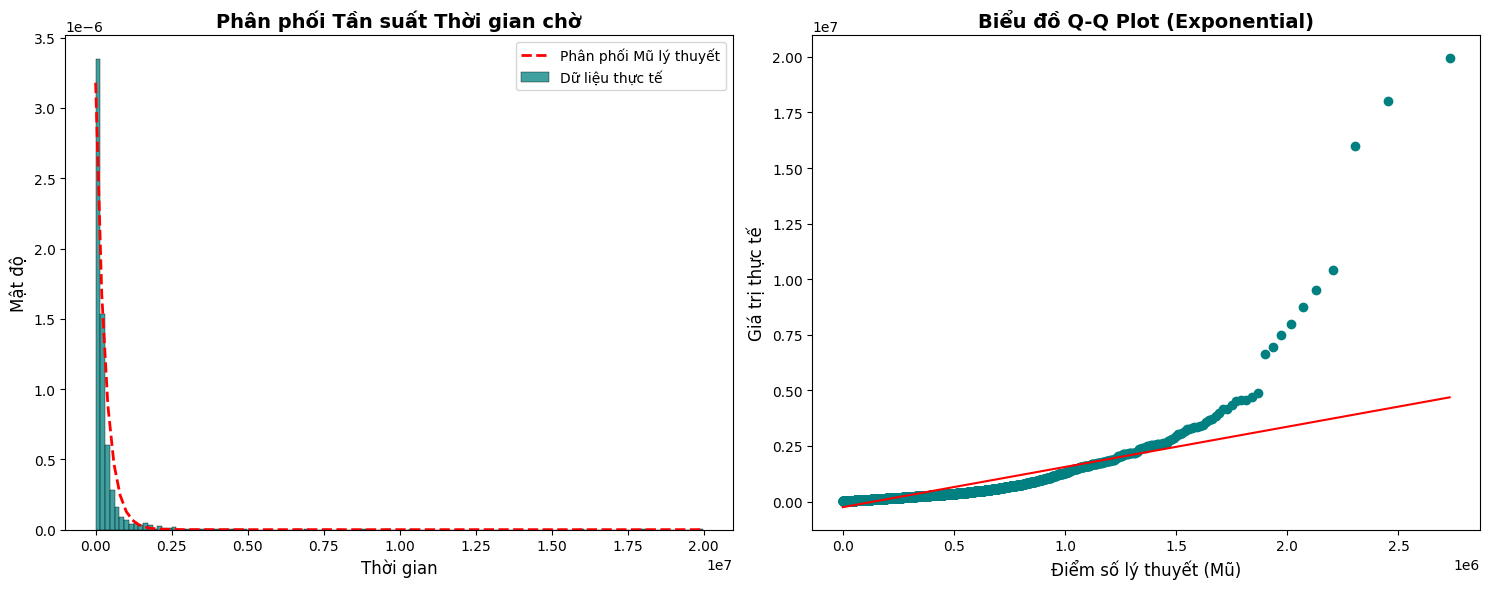

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Biểu đồ 1: Histogram dữ liệu thật vs Đường cong phân phối Mũ lý thuyết
sns.histplot(data, kde=False, stat="density", ax=axes[0], color='teal', label='Dữ liệu thực tế')
x = np.linspace(0, data.max(), 100)
y = stats.expon.pdf(x, loc=0, scale=estimated_scale)
axes[0].plot(x, y, 'r--', linewidth=2, label='Phân phối Mũ lý thuyết')
axes[0].set_title('Phân phối Tần suất Thời gian chờ', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Thời gian', fontsize=12)
axes[0].set_ylabel('Mật độ', fontsize=12)
axes[0].legend()

# Biểu đồ 2: Q-Q Plot thiết kế riêng cho phân phối Mũ (dist="expon")
stats.probplot(data, dist="expon", sparams=(0, estimated_scale), plot=axes[1])
axes[1].get_lines()[0].set_color('teal')
axes[1].get_lines()[1].set_color('red')
axes[1].set_title('Biểu đồ Q-Q Plot (Exponential)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Điểm số lý thuyết (Mũ)', fontsize=12)
axes[1].set_ylabel('Giá trị thực tế', fontsize=12)

plt.tight_layout()
plt.savefig('exponential_analysis.png', dpi=300)
plt.show()

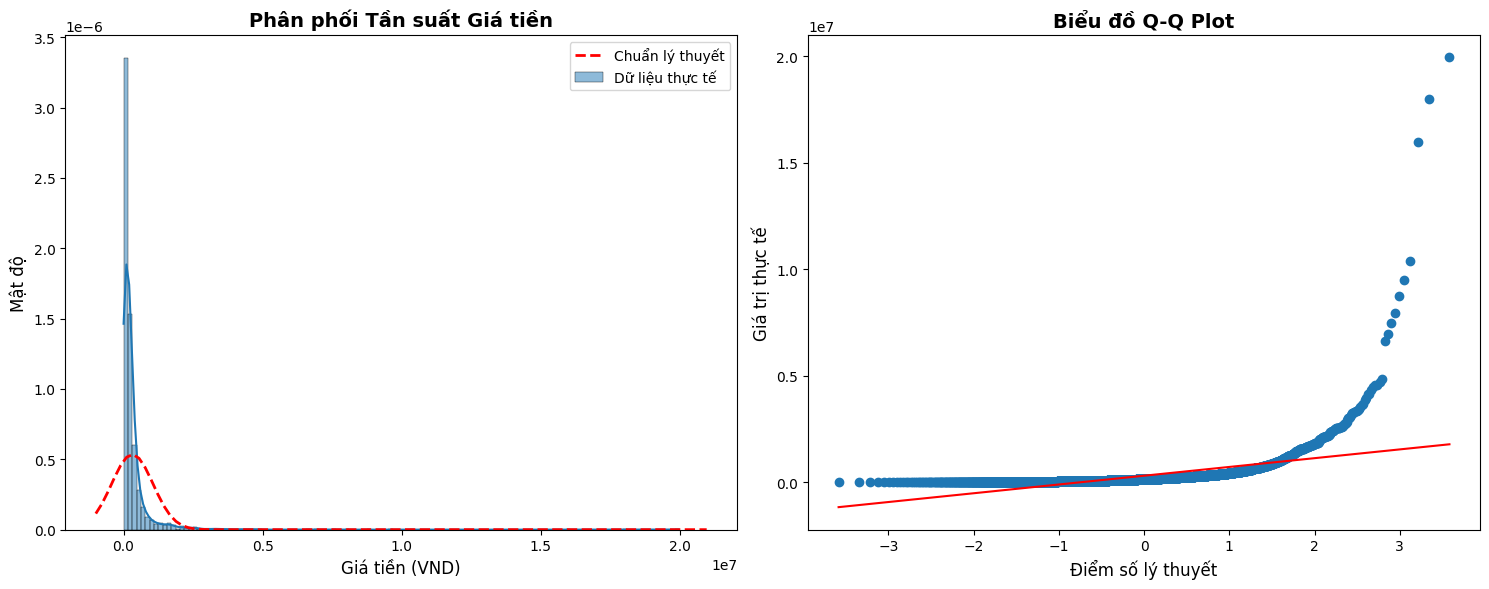

In [22]:
import matplotlib.pyplot as plt
import numpy as np
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Biểu đồ 1 (Bên trái): Histogram kết hợp đường cong mật độ thực tế KDE
sns.histplot(price_data, kde=True, stat="density", ax=axes[0], color='#1f77b4', label='Dữ liệu thực tế')

# Vẽ đè đường cong quả chuông chuẩn lý thuyết (Theoretical Normal) để đối chiếu trực quan
xmin, xmax = axes[0].get_xlim()
x = np.linspace(xmin, xmax, 100)
p = stats.norm.pdf(x, price_data.mean(), price_data.std())
axes[0].plot(x, p, 'r--', linewidth=2, label='Chuẩn lý thuyết')
axes[0].set_title('Phân phối Tần suất Giá tiền', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Giá tiền (VND)', fontsize=12)
axes[0].set_ylabel('Mật độ', fontsize=12)
axes[0].legend()

# Biểu đồ 2 (Bên phải): Q-Q Plot (Quantile-Quantile Plot)
stats.probplot(price_data, dist="norm", plot=axes[1])
axes[1].get_lines()[0].set_color('#1f77b4') # Đổi màu các điểm dữ liệu thật
axes[1].get_lines()[1].set_color('red')     # Đường thẳng chuẩn lý thuyết
axes[1].set_title('Biểu đồ Q-Q Plot', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Điểm số lý thuyết', fontsize=12)
axes[1].set_ylabel('Giá trị thực tế', fontsize=12)

plt.tight_layout()
plt.savefig('price_analysis.png', dpi=300) # Lưu ảnh chất lượng cao
plt.show() # Hiển thị đồ thị

p-value sau khi Log của đồ Tiki: 5.3884e-08


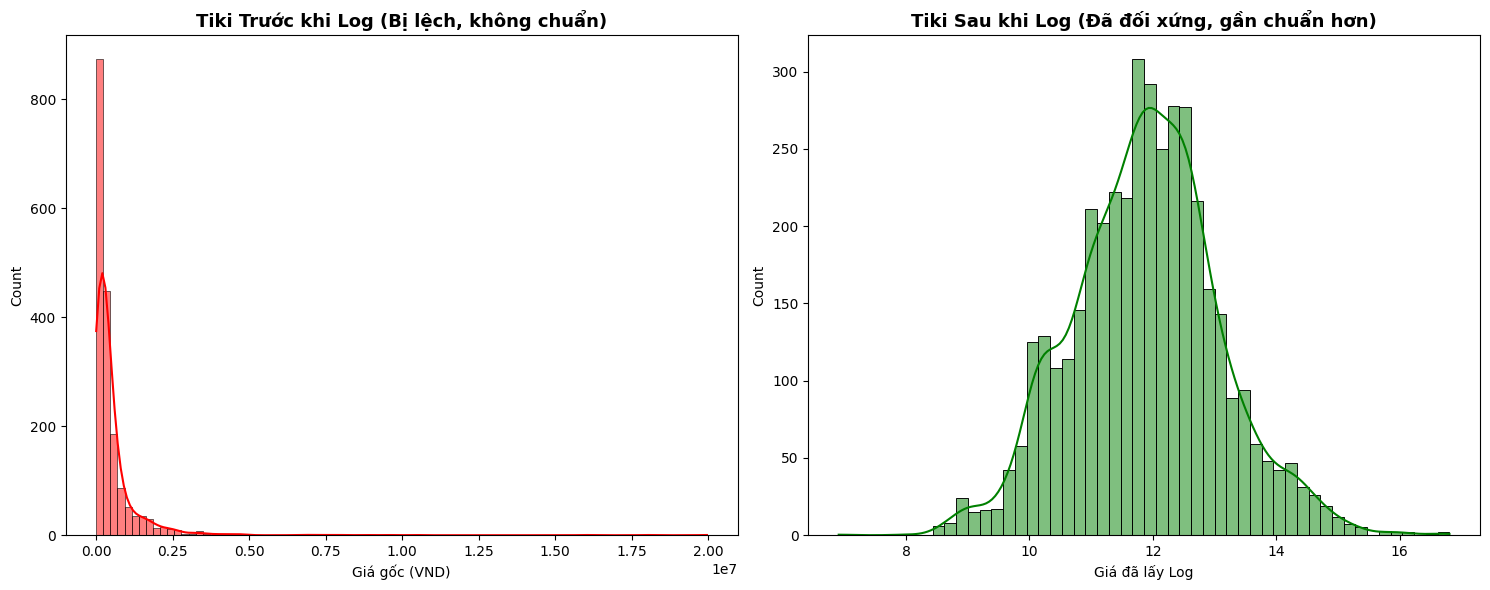

In [47]:


# 1. Áp dụng phép biến đổi Log (ln(x+1)) cho cột price
mask = df['product_id'].str.startswith('tiki', na=False)
df.loc[mask, 'price_log'] = np.log1p(df.loc[mask, 'price'])

shapiro_stat, shapiro_p = stats.shapiro(df['price_log'].dropna())
print(f"p-value sau khi Log của đồ Tiki: {shapiro_p:.4e}")

# 3. Vẽ biểu đồ đối chiếu Trước vs Sau (Chuẩn hóa cùng tập dữ liệu Tiki)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Bên trái: Giá gốc của RIÊNG SẢN PHẨM TIKI
sns.histplot(df.loc[mask, 'price'], kde=True, ax=axes[0], color='red')  # <--- SỬA Ở ĐÂY
axes[0].set_title('Tiki Trước khi Log (Bị lệch, không chuẩn)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Giá gốc (VND)')

# Bên phải: Giá Log của RIÊNG SẢN PHẨM TIKI
sns.histplot(df['price_log'], kde=True, ax=axes[1], color='green')
axes[1].set_title('Tiki Sau khi Log (Đã đối xứng, gần chuẩn hơn)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Giá đã lấy Log')

plt.tight_layout()
plt.savefig('log_transform_result.png', dpi=300)
plt.show()
plt.close()

In [48]:
price_data = df.loc[mask, 'price_log'].dropna()

# =====================================================================
# 2. KIỂM ĐỊNH THỐNG KÊ (Statistical Tests) - Giữ nguyên đoạn dưới của cậu
# =====================================================================
print("="*50)
print(" CHI TIẾT KẾT QUẢ KIỂM ĐỊNH TÍNH CHUẨN (RIÊNG TIKI) ")
print("="*50)

# Kiểm định 1: Shapiro-Wilk Test
shapiro_stat, shapiro_p = stats.shapiro(price_data)
print(f"1. Shapiro-Wilk Test:")
print(f"   - Chỉ số thống kê (Statistic): {shapiro_stat:.4f}")
print(f"   - Giá trị p-value: {shapiro_p:.4e}")

# Kiểm định 2: D'Agostino's K-squared Test
k2_stat, k2_p = stats.normaltest(price_data)
print(f"\n2. D'Agostino's K^2 Test:")
print(f"   - Chỉ số thống kê (Statistic): {k2_stat:.4f}")
print(f"   - Giá trị p-value: {k2_p:.4e}")

# Đưra ra kết luận tự động dựa trên mức ý nghĩa alpha = 0.05
print("-" * 50)
if k2_p < 0.05:
    print("👉 KẾT LUẬN: Bác bỏ giả thuyết H0. Dữ liệu giá TIKI sau khi Log KHÔNG tuân theo phân phối chuẩn.")
else:
    print("👉 KẾT LUẬN: Chưa đủ bằng chứng bác bỏ H0. Dữ liệu giá TIKI sau khi Log TUÂN THEO phân phối chuẩn.")
print("="*50)

 CHI TIẾT KẾT QUẢ KIỂM ĐỊNH TÍNH CHUẨN (RIÊNG TIKI) 
1. Shapiro-Wilk Test:
   - Chỉ số thống kê (Statistic): 0.9974
   - Giá trị p-value: 4.5377e-03

2. D'Agostino's K^2 Test:
   - Chỉ số thống kê (Statistic): 4.1342
   - Giá trị p-value: 1.2655e-01
--------------------------------------------------
👉 KẾT LUẬN: Chưa đủ bằng chứng bác bỏ H0. Dữ liệu giá TIKI sau khi Log TUÂN THEO phân phối chuẩn.


In [50]:
import scipy.stats as stats

# Giả sử cậu đã có price_data gốc (chưa qua mask, đã dropna)
# price_data = df['price'].dropna()

# Bước 1: Ước lượng các tham số của phân phối Lognormal từ dữ liệu thật
# Khóa floc=0 vì giá tiền luôn bắt đầu từ 0 dốc lên
shape, loc, scale = stats.lognorm.fit(price_data, floc=0)

# Bước 2: Chạy kiểm định KS Test trực tiếp trên dữ liệu gốc
ks_stat, ks_p = stats.kstest(price_data, 'lognorm', args=(shape, loc, scale))

print("="*50)
print(" KIỂM ĐỊNH LOGNORMAL TRỰC TIẾP (KS TEST) ")
print("="*50)
print(f"Tham số hình dạng (Shape/Sigma): {shape:.4f}")
print(f"Tham số tỷ lệ (Scale): {scale:.4f}")
print(f"Chỉ số thống kê KS: {ks_stat:.4f}")
print(f"Giá trị p-value: {ks_p:.4e}")
print("-" * 50)

if ks_p < 0.005:
    print("👉 KẾT LUẬN: Dữ liệu gốc KHÔNG tuân theo phân phối Lognormal.")
else:
    print("👉 KẾT LUẬN: Dữ liệu gốc TUÂN THEO phân phối Lognormal.")
print("="*50)

 KIỂM ĐỊNH LOGNORMAL TRỰC TIẾP (KS TEST) 
Tham số hình dạng (Shape/Sigma): 0.0965
Tham số tỷ lệ (Scale): 12.3588
Chỉ số thống kê KS: 0.0354
Giá trị p-value: 1.9641e-02
--------------------------------------------------
👉 KẾT LUẬN: Dữ liệu gốc TUÂN THEO phân phối Lognormal.


In [5]:
# 1. Cài đặt gói zstd bổ sung cho hệ thống Colab (Sửa lỗi chí mạng khiến cài đặt bị dừng)
!sudo apt-get update && sudo apt-get install -y zstd

# 2. Tiến hành cài đặt Ollama vào máy ảo
!curl -fsSL https://ollama.com/install.sh | sh

# 3. Khởi chạy server Ollama chạy ngầm (Background)
import subprocess
import time

print("--> Khởi động server Ollama...")
subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
time.sleep(5) # Tăng lên 5 giây cho chắc chắn server đã ổn định ngầm


Get:1 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease [3,632 B]
Get:2 https://cli.github.com/packages stable InRelease [3,917 B]
Get:3 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  InRelease [1,581 B]
Hit:4 http://archive.ubuntu.com/ubuntu jammy InRelease                         
Get:5 http://security.ubuntu.com/ubuntu jammy-security InRelease [129 kB]      
Get:6 https://r2u.stat.illinois.edu/ubuntu jammy InRelease [6,555 B]           
Get:7 http://archive.ubuntu.com/ubuntu jammy-updates InRelease [128 kB]        
Get:8 https://cli.github.com/packages stable/main amd64 Packages [354 B]       
Get:9 http://archive.ubuntu.com/ubuntu jammy-backports InRelease [127 kB]   
Get:10 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  Packages [2,703 kB]
Get:11 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease [18.1 kB]
Hit:12 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu jammy InRele

In [6]:
!pip install ollama

In [7]:
!ollama pull qwen2.5:7b 

]11;?\pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest 
pulling 2bada8a74506:   0% ▕                  ▏ 255 KB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   1% ▕                  ▏  35 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   2% ▕                  ▏  73 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   3% ▕                  ▏ 157 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   5% ▕                  ▏ 250 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   6% ▕█                 ▏ 293 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   8% ▕█                 ▏ 382 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:  10% ▕█                 ▏ 481 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:  11% ▕██                

In [8]:
!ollama list

]11;?\NAME          ID              SIZE      MODIFIED      
qwen2.5:7b    845dbda0ea48    4.7 GB    5 seconds ago    


In [13]:
import json
import pandas as pd

# 1. Đường dẫn đến file json của bạn trên Kaggle
file_path = "/kaggle/input/datasets/nguynhngthominh/question/_nearfinal_questions.json"

# 2. Đọc file json bằng thư viện json mặc định
with open(file_path, 'r', encoding='utf-8') as f:
    data = json.load(f)

# 3. Chuyển đổi trực tiếp thành DataFrame và lọc cột
df_result = pd.DataFrame.from_dict(data, orient='index')
df_result.head()
df_result.to_csv("result.csv", index=False, encoding='utf-8-sig')

In [14]:
df_result

,image_path,product_id,question,answer_product_id,answer,answer_user_id
CIR-0,images/14/90/149019141_2282526298.jpg,590,"I'm looking for something similar but cheaper,...","[images/40/48/40485634_1965140850.jpg, images/...","[1509, 1352]",NaN
CIR-1,images/11/84/tiki_1184_tikishop_5_big.jpg,tiki_1184,I need some gentle cotton pads like this for d...,[[images/15/40/tiki_1540_tikishop_232_big.jpg]],[tiki_1540],NaN
CIR-2,images/13/27/132753669_6118262128.jpg,1200,Is there a cleanser like this but with natural...,"[images/81/34/81341396_1578921134.jpg, images/...","[41, 115]",NaN
CIR-3,images/36/80/368094170_19735459671.jpg,1819,I've heard CeraVe is good for maintaining the ...,"[images/21/78/217800216_23208227697.mp4, image...","[49, 154, 221, 297]",NaN
CIR-4,images/25/08/250862943_6229593053.jpg,1190,"I'm looking for a gel cleanser for oily, acne-...","[339, 394, 469, 779, 793, 820]","[images/17/55/175572825_4117799148.mp4, images...",NaN
CIR-5,images/77/94/779446567_13995110712.jpg,20,"This looks nice, but do you have a more afford...","[images/82/17/8217147_18424418643.jpg, images/...","[26, 374]",NaN
CIR-6,images/16/01/tiki_1601_tikishop_2_big.jpg,tiki_1601,I prefer well-known brands like NIVEA or Cetap...,"[images/64/09/64099933_10161075948.jpg, images...","[110, 301, 380]",NaN
CIR-7,images/13/77/137785237_2941167148.jpg,1508,I'm looking to buy a La Roche-Posay facial cle...,"[110, 301, 380]","[images/64/09/64099933_10161075948.jpg, images...",NaN
CIR-8,images/34/5_/tiki_345_tikishop_53_big.jpg,tiki_345,I'm looking for a hydrating toner around 200k–...,"[tiki_325, tiki_342]","[images/32/5_/tiki_325_tikishop_88_big.jpg, im...",NaN
CIR-9,images/34/89/348945140_13229186322.mp4,840,I want a gentle facial cleanser made from herb...,"[38, 269, 496]","[images/28/22/28228365_457951140.jpg, images/8...",NaN


In [ ]:
from pydantic import BaseModel, Field
from typing import List, Optional, Literal

class CosmeticQuerySchema(BaseModel):
    brand: Optional[List[str]] = Field(
        default=None, 
        description="List of brand names extracted from the query that match Allowed Brands. Otherwise null."
    )
    origin: Optional[str] = Field(
        default=None, 
        description="Country of origin if explicitly mentioned (e.g., 'South Korea', 'Japan'). Otherwise null."
    )
    price_action: Literal["CHEAPER", "EXPENSIVE", "NONE"] = Field(
        default="NONE",
        description="Direction of price preference compared to the reference product."
    )
    price_range: Optional[List[int]] = Field(
        default=None, 
        description="Explicit price limits parsed into exact integers. E.g., 'around 30k' -> [30000], '200k-300k' -> [200000, 300000]. Otherwise null."
    )
    target_ingredient: Optional[str] = Field(
        default=None, 
        description="Requested cosmetic ingredient or active material (e.g., 'amino acid', 'avocado', 'seaweed'). Otherwise null."
    )
    purpose: Optional[str] = Field(
        default=None, 
        description="The primary benefit, core requirement, or product category (e.g., 'skincare', 'hydration', 'anti-aging'). Otherwise null."
    )
    object: Optional[str] = Field(
        default=None, 
        description="Target user group or specific skin type mentioned (e.g., 'sensitive skin', 'oily skin', 'men'). Otherwise null."
    )
    capacity_action: Optional[Literal["Larger", "Smaller"]] = Field(
        default=None, 
        description="Requested package size/volume action relative to reference or general preference. Otherwise null."
    )

In [11]:
def llm_query_parser(df_database, query_en, ref_product_info):
    
    def normalize_text(text):
        return re.sub(r'[^\w\s]', '', str(text).lower())

    query_normalized = normalize_text(query_en)

    all_brands = df_database['brand'].dropna().unique().tolist()
    filtered_brands = []
    filtered_origins = []
    
    for b in all_brands:
        b_normalized = normalize_text(b)
        if len(b_normalized) > 1:
            pattern = rf"\b{re.escape(b_normalized)}\b"
            if re.search(pattern, query_normalized):
                filtered_brands.append(b)
            
    filtered_brands = list(set(filtered_brands)) 

    all_origins= df_database['origin'].dropna().unique().tolist()
    for b in all_origins:
        b_normalized = normalize_text(b)
        if len(b_normalized) > 1:
            pattern = rf"\b{re.escape(b_normalized)}\b"
            if re.search(pattern, query_normalized):
                filtered_origins.append(b)
    filtered_origins = list(set(filtered_origins))
    
    system_prompt = f"""You are a strict NLP parser for a cosmetic store.
Analyze the user query based on the reference product data.
You MUST extract the information into the exact JSON schema provided.

CRITICAL RULES:
1. "brand": Match with Allowed Brands. Return list of strings, or null.
2. "origin": Extract country of origin if mentioned (e.g., 'South Korea', 'Japan'). Else null.
3. "price_action": "CHEAPER" / "EXPENSIVE" / "NONE".
4. "price_range": Convert 'around 30k' to [30000], '200k-300k' to [200000, 300000]. Else null.
5. "target_ingredient": Extract requested ingredient/material (e.g., 'amino acid', 'avocado', "seaweed). Else null.
6. "purpose": Extract keyword for benefit or requirement (e.g., 'skincare', 'hydration', 'anti-aging'). Else null.
8. "object": Extract skin type or target user (e.g., 'sensitive skin', 'oily skin', 'men'). Else null.
9. "capacity_action: Extract action requested related to capacity(e.g 'Larger', 'Smaller')

ALLOWED BRANDS: {filtered_brands}
ALLOWED ORIGIN: {filtered_origins}"""

    user_content = f"""[ACTUAL DATA TO PARSE]:
- Ref Product: {{"price": {ref_product_info.get('price', 0)}, "brand": "{ref_product_info.get('brand', '')}", "ingredient": "{ref_product_info.get('ingredient', '')}"}}
- Query: "{query_en}" """
    response = ollama.chat(
        model='qwen2.5:7b',
        messages=[
            {'role': 'system', 'content': system_prompt},
            {'role': 'user', 'content': user_content}
        ],
        format=CosmeticQuerySchema.model_json_schema(),
        options={
            'temperature': 0.0,
            'num_predict': 150
        }
    )

    llm_output = response['message']['content'].strip()

    try:
        parsed_json = json.loads(llm_output)
    except:
        parsed_json = {}

    # Đảm bảo có đủ key trong dict đầu ra
    required_keys = ["brand", "origin", "price_action", "price_range", "target_ingredient", "purpose", "object", "capacity_action"]
    for key in required_keys:
        if key not in parsed_json:
            parsed_json[key] = None

    # Hậu xử lý cho Brand
    if parsed_json.get("brand") in [None, "null", []]:
        if filtered_brands:
            parsed_json["brand"] = [str(b) for b in filtered_brands]
        else:
            parsed_json["brand"] = None
    elif isinstance(parsed_json["brand"], str):
        parsed_json["brand"] = [parsed_json["brand"]]

    # Hậu xử lý cho Object (Thêm "all skin types")
    if parsed_json.get("object") not in [None, "null", ""]:
        current_obj = parsed_json["object"]
        if isinstance(current_obj, list):
            if "all skin types" not in current_obj:
                current_obj.append("all skin types")
            parsed_json["object"] = current_obj
        else:
            parsed_json["object"] = [current_obj, "all skin types"]
    else:
        # Nếu user không yêu cầu skin type cụ thể nào, giữ nguyên None để dễ filter database về sau
        parsed_json["object"] = None

    return parsed_json

In [12]:
print(df.columns)


Index(['product_id', 'image_path', 'product_name', 'translated_description',
       'price', 'brand', 'origin', 'object', 'ingredient', 'capacity',
       'purpose', 'checked', 'normalized_price'],
      dtype='object')


In [50]:
import pandas as pd
from tqdm import tqdm 
import ollama
tqdm.pandas()

def process_row(row):
    """
    Hàm bổ trợ xử lý cho từng dòng của df_result
    """
    query_en = row['question']
    prod_id = row['product_id']
    
    ref_product = df[df['product_id'] == prod_id]
    
    if not ref_product.empty:
        ref_product_info = ref_product.iloc[0].to_dict()
    else:
        ref_product_info = {"price": 0, "brand": "", "ingredient": ""}
        
    try:
        parsed_data = llm_query_parser(df, query_en, ref_product_info)
        return pd.Series(parsed_data)
    except Exception as e:
        print(f"Lỗi tại dòng này: {e}")  
        return pd.Series({
            "brand": None, "origin": None, "price_action": None, 
            "price_range": None, "target_ingredient": None, 
            "purpose": None, "object": None, "capacity_action": None
        })


print("Đang tiến hành parse toàn bộ câu hỏi bằng LLM Qwen...")
parsed_columns = df_result.progress_apply(process_row, axis=1)

df_final = pd.concat([df_result, parsed_columns], axis=1)

print("\n--- KẾT QUẢ SAU KHI PARSE CHẠY THỬ ---")
print(df_final)

df_final.to_csv("parsed_questions.csv", index=False, encoding='utf-8-sig')

ModuleNotFoundError: No module named 'ollama'

In [14]:
print(df.columns)

Index(['product_id', 'image_path', 'product_name', 'translated_description',
       'price', 'brand', 'origin', 'object', 'ingredient', 'capacity',
       'purpose', 'checked', 'normalized_price'],
      dtype='object')


# TEST THỬ 

In [24]:
df[df['product_id']=='590']

,product_id,image_path,product_name,translated_description,price,brand,origin,object,ingredient,capacity,purpose,type,normalized_price
590,590,149019141_2282526298.jpg,"Ponds 100g Facial Cleanser with Three Variants for Different Skin Types, suu.shop Guarantees 100% Authentic.","Su Shop always brings customers trust in products and service quality. Su Shop specializes in providing genuine cosmetics, offering 10 genuine, sealed perfumes, and accepting returns/exchanges if the product delivered by the shop is fake, counterfeit, or defective.\n\nPond's Oil Control Facial Cleanser: Cleanses and nourishes skin for a bright,",62350,Pond’s,Vietnam,all skin types,NaN,100g,"Facial Cleanser, oil control, brighten",foam,0.003074


In [7]:
# =====================================================================
# MODULE 1: RULE-BASED QUERY PARSER (Tối ưu từ hàm của bạn)
# =====================================================================
def advanced_query_parser(df_database, query_en, ref_price=None):
    constraints = {
        "brand": None,
        "origin": None,
        "price_min": None,
        "price_max": None,
        "target_ingredient": None,
        "purpose": None,
        "object": None
    }

    # Chuẩn hóa văn bản câu hỏi
    query_clean = query_en.lower().replace('–', '-').replace("'", '’')
    # Tách từ để dùng cho so khớp chính xác (tránh dính seaweed vào sea)
    query_words = re.sub(r'[^\w\s-]', '', query_clean).split()

    # 1. Trích xuất Brand (Dùng Regex Word Boundary để tránh dính chuỗi con)
    known_brands_list = df_database['brand'].dropna().unique().tolist()
    for b in known_brands_list:
        pattern = rf"\b{re.escape(b.lower())}\b"
        if re.search(pattern, query_clean):
            constraints["brand"] = [b]  # Trả về dạng list để đồng bộ logic .isin()
            break

    # 2. Trích xuất Origin
    known_origin_list = df_database['origin'].dropna().unique().tolist()
    for o in known_origin_list:
        pattern = rf"\b{re.escape(o.lower())}\b"
        if re.search(pattern, query_clean):
            constraints["origin"] = o
            break

    # 3. Trích xuất Khoảng Giá (Price Extraction)
    price_matches = re.findall(r'(\d+)\s*k', query_clean)
    if len(price_matches) >= 2:
        constraints["price_min"] = int(price_matches[0]) * 1000
        constraints["price_max"] = int(price_matches[1]) * 1000
    elif len(price_matches) == 1:
        specific_price = int(price_matches[0]) * 1000
        constraints["price_min"] = int(specific_price * 0.8)
        constraints["price_max"] = int(specific_price * 1.2)
    elif ref_price is not None:
        is_cheaper = any(word in query_clean for word in ['cheaper', 'affordable', 'lower price', 'less expensive', 'budget', 'cheap'])
        is_expensive = any(word in query_clean for word in ['expensive', 'premium', 'higher price', 'luxury', 'high-end'])

        if is_cheaper:
            constraints["price_min"] = 0
            constraints["price_max"] = max(0, int(ref_price) - 1)
        elif is_expensive:
            constraints["price_min"] = int(ref_price) + 1
            constraints["price_max"] = float('inf')

    # 4. Trích xuất một số từ khóa phổ biến cho Ingredient/Purpose/Object (Mở rộng thêm nếu cần)
    # Vì không dùng LLM, các trường này sẽ được trích xuất thô nếu xuất hiện trong câu hỏi
    common_ingredients = ['avocado', 'seaweed', 'amino acid', 'centella', 'aloe', 'retinol', 'vitamin c', 'b5', 'pH 5.5']
    for ing in common_ingredients:
        if ing in query_clean:
            constraints["target_ingredient"] = ing
            break

    common_purposes = ['hydration', 'hydrating', 'cleansing', 'anti-aging', 'skincare', 'acne care', 'whitening']
    for pur in common_purposes:
        if pur in query_clean:
            constraints["purpose"] = pur
            break

    common_objects = ['sensitive skin', 'oily skin', 'acne-prone skin', 'dry skin', 'combination skin', 'men']
    for obj in common_objects:
        if obj in query_clean:
            constraints["object"] = obj
            break

    return constraints

In [ ]:
import pandas as pd
import numpy as np
import re
from sklearn.metrics.pairwise import cosine_similarity

def retrieve_and_rank(df_database, ref_product_id, parsed_row, top_k=15):
    """
    Hàm retrieval phân tầng kết quả: 
    - Ưu tiên 1: Đúng dải giá chuẩn (Xếp hạng theo similarity).
    - Ưu tiên 2: Dải giá nới lỏng 20% nếu thiếu hàng (Xếp hạng theo similarity và đẩy xuống dưới).
    """
    ref_id = str(ref_product_id).split('.')[0].strip() 
    
    # Tìm sản phẩm gốc trong database
    ref_rows = df_database[df_database['product_id'].astype(str).str.split('.').str[0].str.strip() == ref_id]
    if ref_rows.empty:
        print(f"--> [LỖI]: Không tìm thấy sản phẩm gốc với ID: {ref_id} trong df_database!")
        return pd.DataFrame()
        
    ref_product = ref_rows.iloc[0]

    # Bốc constraints từ Excel
    brand_target = parsed_row.get("brand")
    origin_target = parsed_row.get("origin")
    price_range_raw = parsed_row.get("price_range")
    price_action = parsed_row.get("price_action")
    
    # Tạo bảng ứng viên ban đầu (Loại trừ sản phẩm gốc)
    base_candidates = df_database[df_database['product_id'].astype(str).str.split('.').str[0].str.strip() != ref_id].copy()

    # =====================================================================
    # BƯỚC 1: LỌC THƯƠNG HIỆU & XUẤT XỨ (Giữ nguyên logic chuẩn hóa sạch)
    # =====================================================================
    if pd.notna(brand_target) and str(brand_target).lower() not in ['nan', 'null', '']:
        def clean_brand_string(s):
            s = str(s).lower()
            s = re.sub(r"[’’'\"\[\]]", "", s)
            return s.strip()

        if isinstance(brand_target, (str, list, np.ndarray)):
            if isinstance(brand_target, str):
                raw_brands = [b.strip() for b in brand_target.split(',')]
            else:
                raw_brands = [str(b) for b in brand_target]
            brand_clean_list = [clean_brand_string(b) for b in raw_brands if b.strip() != '']
            database_brands_clean = base_candidates['brand'].astype(str).apply(clean_brand_string)
            base_candidates = base_candidates[database_brands_clean.isin(brand_clean_list)]

    if pd.notna(origin_target) and str(origin_target).lower() not in ['nan', 'null', '']:
        base_candidates = base_candidates[base_candidates['origin'].astype(str).str.lower() == str(origin_target).lower()]

    # =====================================================================
    # BƯỚC 2: PHÂN TÁCH KHOẢNG GIÁ (CỨNG VÀ NỚI LỎNG)
    # =====================================================================
    is_valid_price = False
    if price_range_raw is not None:
        if isinstance(price_range_raw, (np.ndarray, list)):
            is_valid_price = len(price_range_raw) > 0
        else:
            is_valid_price = pd.notna(price_range_raw)

    nums = [int(s) for s in re.findall(r'\d+', str(price_range_raw))] if is_valid_price else []

    price_min_strict, price_max_strict = None, None
    price_min_relaxed, price_max_relaxed = None, None

    # Xác định các biên độ giá
    if len(nums) == 1:
        price_min_strict, price_max_strict = int(nums[0] * 0.9), int(nums[0] * 1.1)
        price_min_relaxed, price_max_relaxed = int(nums[0] * 0.8), int(nums[0] * 1.2)
    elif len(nums) >= 2:
        price_min_strict, price_max_strict = int(min(nums)), int(max(nums))
        price_min_relaxed, price_max_relaxed = int(min(nums) * 0.8), int(max(nums) * 1.2)
    elif price_action == "CHEAPER":
        price_min_strict, price_max_strict = 0, max(0, int(ref_product['price']) - 1)
        price_min_relaxed, price_max_relaxed = 0, max(0, int(ref_product['price'] * 1.2))
    elif price_action == "EXPENSIVE":
        price_min_strict, price_max_strict = int(ref_product['price']) + 1, float('inf')
        price_min_relaxed, price_max_relaxed = int(ref_product['price'] * 0.8), float('inf')

    # Chia tập ứng viên thành 2 nhóm dựa trên giá
    if price_min_strict is not None and price_max_strict is not None:
        strict_candidates = base_candidates[
            (base_candidates['price'] >= price_min_strict) & (base_candidates['price'] <= price_max_strict)
        ].copy()
        
        relaxed_candidates = base_candidates[
            (base_candidates['price'] >= price_min_relaxed) & (base_candidates['price'] <= price_max_relaxed) &
            ~((base_candidates['price'] >= price_min_strict) & (base_candidates['price'] <= price_max_strict))
        ].copy()
    else:
        strict_candidates = base_candidates.copy()
        relaxed_candidates = pd.DataFrame()

    # Gom các ứng viên hợp lệ lại để tính toán điểm số một lượt cho nhanh
    all_selected_candidates = pd.concat([strict_candidates, relaxed_candidates]).drop_duplicates(subset=['product_id'])

    if all_selected_candidates.empty:
        print("--> Không tìm thấy sản phẩm nào phù hợp kể cả sau khi nới giá!")
        return pd.DataFrame()

    # =====================================================================
    # BƯỚC 3: TÁI XẾP HẠNG NGỮ NGHĨA VECTOR MỘT LƯỢT
    # =====================================================================
    def clean_val(v):
        if pd.isna(v) or str(v).lower() in ['nan', 'null', '']: return ""
        return str(v).replace('[', '').replace(']', '').replace("'", "")

    ref_text_parts = [
        str(parsed_row['question'])
    ]
    ref_text_parts.append(clean_val(parsed_row.get('object')))
    ref_text_parts.append(clean_val(parsed_row.get('purpose')))
    ref_text_parts.append(clean_val(parsed_row.get('target_ingredient')))

    ref_text = " . ".join([p for p in ref_text_parts if p.strip() != ''])
    ref_embedding = model.encode([ref_text])

    candidate_texts = (
        all_selected_candidates['product_name'].fillna('') + " . " +
        all_selected_candidates['type'].fillna('') + " . " +
        all_selected_candidates['object'].fillna('') + " . " +      
        all_selected_candidates['ingredient'].fillna('') + " . " +  
        all_selected_candidates['purpose'].fillna('')
    ).tolist()

    candidate_embeddings = model.encode(candidate_texts)
    scores = cosine_similarity(ref_embedding, candidate_embeddings)[0]
    all_selected_candidates['similarity_score'] = scores

    # =====================================================================
    # BƯỚC 4: THỰC HIỆN PHÂN TẦNG VÀ GHÉP MẢNG (GIẢI QUYẾT BÀI TOÁN CỦA BẠN)
    # =====================================================================
    if relaxed_candidates.empty:
        print(f"--> [Kết quả phân tầng]: Đúng giá chuẩn: {len(strict_candidates)} | Giá nới lỏng: 0")
        final_output = all_selected_candidates.sort_values(by='similarity_score', ascending=False)
        return final_output.head(top_k)
        
    final_strict = all_selected_candidates[all_selected_candidates.index.isin(strict_candidates.index)].copy()
    final_relaxed = all_selected_candidates[all_selected_candidates.index.isin(relaxed_candidates.index)]
                                                                               
    final_strict = final_strict.sort_values(by='similarity_score', ascending=False)
    final_relaxed = final_relaxed.sort_values(by='similarity_score', ascending=False)
    final_output = pd.concat([final_strict, final_relaxed])
    return final_output.head(top_k)

In [8]:
import pandas as pd
import ast

def parse_list_col(val):
    if pd.isna(val) or val == "" or val == "null":
        return None
    try:
        return ast.literal_eval(str(val))
    except:
        return val

try:
    df_parsed_questions = pd.read_csv(
        "/kaggle/input/datasets/nguynhngthominh/question/parsed_questions.csv", 
        encoding='latin1',  
        converters={
            "brand": parse_list_col,
            "price_range": parse_list_col
        }
    )
except UnicodeDecodeError:
    # Phương án dự phòng nếu latin1 vẫn sót ký tự lạ khác
    df_parsed_questions = pd.read_csv(
        "/kaggle/input/datasets/nguynhngthominh/question/parsed_questions.csv", 
        encoding='windows-1252',
        converters={
            "brand": parse_list_col,
            "price_range": parse_list_col
        }
    )

print(f"Đã tải thành công {len(df_parsed_questions)} câu hỏi từ file CSV!")

Đã tải thành công 20 câu hỏi từ file CSV!


In [9]:
def retrieve_and_rank(df_database, ref_product_id, parsed_row, top_k=15):
    """
    Hàm retrieval phân tầng kết quả: 
    - Ưu tiên 1: Đúng dải giá chuẩn (Xếp hạng theo similarity).
    - Ưu tiên 2: Dải giá nới lỏng 20% nếu thiếu hàng (Xếp hạng theo similarity và đẩy xuống dưới).
    """
    ref_id = str(ref_product_id).split('.')[0].strip() 
    
    # Tìm sản phẩm gốc trong database
    ref_rows = df_database[df_database['product_id'].astype(str).str.split('.').str[0].str.strip() == ref_id]
    if ref_rows.empty:
        print(f"--> [LỖI]: Không tìm thấy sản phẩm gốc với ID: {ref_id} trong df_database!")
        return pd.DataFrame()
        
    ref_product = ref_rows.iloc[0]

    # Bốc constraints từ Excel
    brand_target = parsed_row.get("brand")
    origin_target = parsed_row.get("origin")
    price_range_raw = parsed_row.get("price_range")
    price_action = parsed_row.get("price_action")
    capacity_action = parsed_row.get("capacity_action")
    
    # Tạo bảng ứng viên ban đầu (Loại trừ sản phẩm gốc)
    base_candidates = df_database[df_database['product_id'].astype(str).str.split('.').str[0].str.strip() != ref_id].copy()

    # =====================================================================
    # BƯỚC 1: LỌC THƯƠNG HIỆU & XUẤT XỨ (Giữ nguyên logic chuẩn hóa sạch)
    # =====================================================================
    if pd.notna(brand_target) and str(brand_target).lower() not in ['nan', 'null', '']:
        def clean_brand_string(s):
            s = str(s).lower()
            s = re.sub(r"[’’'\"\[\]]", "", s)
            return s.strip()

        if isinstance(brand_target, (str, list, np.ndarray)):
            if isinstance(brand_target, str):
                raw_brands = [b.strip() for b in brand_target.split(',')]
            else:
                raw_brands = [str(b) for b in brand_target]
            brand_clean_list = [clean_brand_string(b) for b in raw_brands if b.strip() != '']
            database_brands_clean = base_candidates['brand'].astype(str).apply(clean_brand_string)
            base_candidates = base_candidates[database_brands_clean.isin(brand_clean_list)]

    if pd.notna(origin_target) and str(origin_target).lower() not in ['nan', 'null', '']:
        base_candidates = base_candidates[base_candidates['origin'].astype(str).str.lower() == str(origin_target).lower()]

    # =====================================================================
    # BƯỚC 2: PHÂN TÁCH KHOẢNG GIÁ VÀ DUNG TÍCH (CAPACITY ACTION)
    # =====================================================================
    def extract_capacity_value(capacity_str):
        if pd.isna(capacity_str): return None
        match = re.search(r'(\d+(?:\.\d+)?)\s*(ml|g|gram)', str(capacity_str).lower())
        if match:
            return float(match.group(1))
        return None

    if str(capacity_action).upper() == "LARGER":
        ref_cap = extract_capacity_value(ref_product.get('capacity'))
        if ref_cap is not None:
            def filter_larger_capacity(row):
                cand_cap = extract_capacity_value(row['capacity'])
                if cand_cap is not None:
                    return cand_cap > ref_cap
                return False
            base_candidates = base_candidates[base_candidates.apply(filter_larger_capacity, axis=1)]
    is_valid_price = False
    if price_range_raw is not None:
        if isinstance(price_range_raw, (np.ndarray, list)):
            is_valid_price = len(price_range_raw) > 0
        else:
            is_valid_price = pd.notna(price_range_raw)

    nums = [int(s) for s in re.findall(r'\d+', str(price_range_raw))] if is_valid_price else []

    price_min_strict, price_max_strict = None, None
    price_min_relaxed, price_max_relaxed = None, None

    # THỨ TỰ ƯU TIÊN MỚI:
    if len(nums) == 1:
        # Nếu khách nói "under 120k" hoặc "around 120k"
        if price_action == "CHEAPER" or "under" in str(test_query).lower() or "less" in str(test_query).lower():
            # Trường hợp "Dưới 120k": dải strict từ 0 -> 120k, relaxed nới thêm 20% trần
            price_min_strict, price_max_strict = 0, int(nums[0])
            price_min_relaxed, price_max_relaxed = 0, int(nums[0] * 1.2)
        else:
            # Trường hợp "Khoảng 120k" (Giữ nguyên logic cũ của cậu)
            price_min_strict, price_max_strict = int(nums[0] * 0.9), int(nums[0] * 1.1)
            price_min_relaxed, price_max_relaxed = int(nums[0] * 0.8), int(nums[0] * 1.2)
            
    elif len(nums) >= 2:
        price_min_strict, price_max_strict = int(min(nums)), int(max(nums))
        price_min_relaxed, price_max_relaxed = int(min(nums) * 0.8), int(max(nums) * 1.2)
        
    elif price_action == "CHEAPER":
        # Nếu không có số cụ thể, chỉ nói "rẻ hơn chai cũ"
        price_min_strict, price_max_strict = 0, max(0, int(ref_product['price']) - 1)
        price_min_relaxed, price_max_relaxed = 0, max(0, int(ref_product['price'] * 1.2))
        
    elif price_action == "EXPENSIVE":
        price_min_strict, price_max_strict = int(ref_product['price']) + 1, float('inf')
        price_min_relaxed, price_max_relaxed = int(ref_product['price'] * 0.8), float('inf')
    
    else:
        strict_candidates = base_candidates.copy()
        relaxed_candidates = pd.DataFrame()

    all_selected_candidates = pd.concat([strict_candidates, relaxed_candidates]).drop_duplicates(subset=['product_id'])

    if all_selected_candidates.empty:
        print("--> Không tìm thấy sản phẩm nào phù hợp kể cả sau khi nới giá!")
        return pd.DataFrame()

    # =====================================================================
    # BƯỚC 3: TÁI XẾP HẠNG NGỮ NGHĨA VECTOR MỘT LƯỢT
    # =====================================================================
    def clean_val(v):
        if pd.isna(v) or str(v).lower() in ['nan', 'null', '']: return ""
        return str(v).replace('[', '').replace(']', '').replace("'", "")

    ref_text_parts = [
        str(parsed_row['question'])
    ]
    ref_text_parts.append(clean_val(parsed_row.get('object')))
    ref_text_parts.append(clean_val(parsed_row.get('purpose')))
    ref_text_parts.append(clean_val(parsed_row.get('target_ingredient')))

    ref_text = " . ".join([p for p in ref_text_parts if p.strip() != ''])
    ref_embedding = model.encode([ref_text])

    candidate_texts = (
        all_selected_candidates['product_name'].fillna('') + " . " +
        all_selected_candidates['type'].fillna('') + " . " +
        all_selected_candidates['object'].fillna('') + " . " +      
        all_selected_candidates['ingredient'].fillna('') + " . " +  
        all_selected_candidates['purpose'].fillna('')
    ).tolist()

    candidate_embeddings = model.encode(candidate_texts)
    scores = cosine_similarity(ref_embedding, candidate_embeddings)[0]
    all_selected_candidates['similarity_score'] = scores

    # =====================================================================
    # BƯỚC 4: THỰC HIỆN PHÂN TẦNG VÀ GHÉP MẢNG (GIẢI QUYẾT BÀI TOÁN CỦA BẠN)
    # =====================================================================
    if relaxed_candidates.empty:
        print(f"--> [Kết quả phân tầng]: Đúng giá chuẩn: {len(strict_candidates)} | Giá nới lỏng: 0")
        final_output = all_selected_candidates.sort_values(by='similarity_score', ascending=False)
        return final_output.head(top_k)
        
    final_strict = all_selected_candidates[all_selected_candidates.index.isin(strict_candidates.index)].copy()
    final_relaxed = all_selected_candidates[all_selected_candidates.index.isin(relaxed_candidates.index)]
                                                                                                                
    final_strict = final_strict.sort_values(by='similarity_score', ascending=False)
    final_relaxed = final_relaxed.sort_values(by='similarity_score', ascending=False)
    final_output = pd.concat([final_strict, final_relaxed])
    return final_output.head(top_k)

In [17]:
print(df.columns.tolist())


['product_id', 'image_path', 'product_name', 'translated_description', 'price', 'brand', 'origin', 'object', 'ingredient', 'capacity', 'purpose', 'type', 'normalized_price']


In [10]:
# QUERY 1
if __name__ == "__main__":
    
    queries = "I'm looking for something similar but cheaper, around 40k–50k, preferably still from Pond’s."
    cir_id = "590"

    print("\n" + "="*60)
    print(f"ĐANG CHẠY: {cir_id}")
    # The cir_id itself is the product_id, so no need to use .iloc
    actual_ref_product_id = cir_id
    print(f"Sản phẩm gốc ID: {actual_ref_product_id}")
    print(f"Câu hỏi: {queries}")

    # Chạy Framework tìm kiếm
    top_suggestions = retrieve_and_rank(
        df_database=df,
        ref_product_id=actual_ref_product_id, 
        query_en= queries,
        top_k=20 
    )

    # In kết quả gợi ý ra màn hình
    if top_suggestions.empty:
        print(f"--> KẾT QUẢ: Không tìm thấy sản phẩm nào khớp với bộ lọc cứng của câu hỏi này.")
        print(f"Tổng số kết quả: {len(top_suggestions)}")
    else:
        print(f"--> KẾT QUẢ TOP {len(top_suggestions)} SẢN PHẨM GỢI Ý:")
        df_results= pd.DataFrame(top_suggestions)
        display(df_results)


ĐANG CHẠY: 590
Sản phẩm gốc ID: 590
Câu hỏi: I'm looking for something similar but cheaper, around 40k–50k, preferably still from Pond’s.


TypeError: retrieve_and_rank() got an unexpected keyword argument 'query_en'

In [ ]:
# QUERY 2
if __name__ == "__main__":

    queries = "I need some gentle cotton pads like this for daily skincare, preferably 100% natural and not irritating to sensitive skin."
    cir_id = "tiki_1540"

    print("\n" + "="*60)
    print(f"ĐANG CHẠY: {cir_id}")
    # The cir_id itself is the product_id, so no need to use .iloc
    actual_ref_product_id = cir_id
    print(f"Sản phẩm gốc ID: {actual_ref_product_id}")
    print(f"Câu hỏi: {queries}")

    # Chạy Framework tìm kiếm
    top_suggestions = retrieve_and_rank(
        df_database=df,
        ref_product_id=actual_ref_product_id, 
        query_en= queries,
        top_k=20 
    )

    # In kết quả gợi ý ra màn hình
    if top_suggestions.empty:
        print("--> KẾT QUẢ: Không tìm thấy sản phẩm nào khớp với bộ lọc cứng của câu hỏi này.")
        print("Tổng số kết quả: {len(top_suggestions)}")
    else:
        print(f"--> KẾT QUẢ TOP {len(top_suggestions)} SẢN PHẨM GỢI Ý:")
        df_results= pd.DataFrame(top_suggestions)
        display(df_results)

In [ ]:
# QUERY 6
if __name__ == "__main__":

    # 2. Load các câu hỏi test mẫu (file JSON bạn gửi)
    queries = "I prefer well-known brands like NIVEA or Cetaphil. Do you have a gentle cleanser similar in quality to this product?"
    cir_id = "tiki_1601"

    print("\n" + "="*60)
    print(f"ĐANG CHẠY: {cir_id}")
    # The cir_id itself is the product_id, so no need to use .iloc
    actual_ref_product_id = cir_id
    print(f"Sản phẩm gốc ID: {actual_ref_product_id}")
    print(f"Câu hỏi: {queries}")

    # Chạy Framework tìm kiếm
    top_suggestions = retrieve_and_rank(
        df_database=df,
        ref_product_id=actual_ref_product_id, 
        query_en= queries,
        top_k=20 
    )

    # In kết quả gợi ý ra màn hình
    if top_suggestions.empty:
        print("--> KẾT QUẢ: Không tìm thấy sản phẩm nào khớp với bộ lọc cứng của câu hỏi này.")
        print("Tổng số kết quả: {len(top_suggestions)}")
    else:
        print(f"--> KẾT QUẢ TOP {len(top_suggestions)} SẢN PHẨM GỢI Ý:")
        df_results= pd.DataFrame(top_suggestions)
        display(df_results)

In [ ]:
# QUERY 8
if __name__ == "__main__":

    # 2. Load các câu hỏi test mẫu (file JSON bạn gửi)
    queries = "I'm looking for a hydrating toner around 200k–300k VND that deeply moisturizes and soothes sensitive skin, preferably with natural marine ingredients like seaweed or minerals. Which products match this need?"
    cir_id = "tiki_345"

    print("\n" + "="*60)
    print(f"ĐANG CHẠY: {cir_id}")
    # The cir_id itself is the product_id, so no need to use .iloc
    actual_ref_product_id = cir_id
    print(f"Sản phẩm gốc ID: {actual_ref_product_id}")
    print(f"Câu hỏi: {queries}")

    # Chạy Framework tìm kiếm
    top_suggestions = retrieve_and_rank(
        df_database=df,
        ref_product_id=actual_ref_product_id, 
        query_en= queries,
        top_k=20 
    )

    # In kết quả gợi ý ra màn hình
    if top_suggestions.empty:
        print("--> KẾT QUẢ: Không tìm thấy sản phẩm nào khớp với bộ lọc cứng của câu hỏi này.")
        print("Tổng số kết quả: {len(top_suggestions)}")
    else:
        print(f"--> KẾT QUẢ TOP {len(top_suggestions)} SẢN PHẨM GỢI Ý:")
        df_results= pd.DataFrame(top_suggestions)
        display(df_results)

In [ ]:
import pandas as pd
import numpy as np
import re
from sklearn.metrics.pairwise import cosine_similarity

def retrieve_and_rank(df_database, ref_product_id, parsed_row, top_k=15):
    """
    Hàm retrieval phân tầng kết quả tối ưu:
    - Sửa triệt để lỗi UnboundLocalError bằng cách kết khối if/elif/else đồng bộ.
    - Tích hợp bộ lọc dung tích capacity_action.
    - Xử lý thông minh bài toán biên giá khi kết hợp price_action và price_range.
    """
    ref_id = str(ref_product_id).split('.')[0].strip() 
    
    ref_rows = df_database[df_database['product_id'].astype(str).str.split('.').str[0].str.strip() == ref_id]
    if ref_rows.empty:
        print(f"--> [LỖI]: Không tìm thấy sản phẩm gốc với ID: {ref_id} trong df_database!")
        return pd.DataFrame()
        
    ref_product = ref_rows.iloc[0]

    brand_target = parsed_row.get("brand")
    origin_target = parsed_row.get("origin")
    price_range_raw = parsed_row.get("price_range")
    price_action = parsed_row.get("price_action")
    capacity_action = parsed_row.get("capacity_action")
    
    base_candidates = df_database[df_database['product_id'].astype(str).str.split('.').str[0].str.strip() != ref_id].copy()

    # =====================================================================
    # BƯỚC 1: LỌC THƯƠNG HIỆU & XUẤT XỨ
    # =====================================================================
    if pd.notna(brand_target) and str(brand_target).lower() not in ['nan', 'null', '']:
        def clean_brand_string(s):
            s = str(s).lower()
            s = re.sub(r"[’’'\"\[\]]", "", s)
            return s.strip()

        if isinstance(brand_target, (str, list, np.ndarray)):
            if isinstance(brand_target, str):
                raw_brands = [b.strip() for b in brand_target.split(',')]
            else:
                raw_brands = [str(b) for b in brand_target]
            brand_clean_list = [clean_brand_string(b) for b in raw_brands if b.strip() != '']
            database_brands_clean = base_candidates['brand'].astype(str).apply(clean_brand_string)
            base_candidates = base_candidates[database_brands_clean.isin(brand_clean_list)]

    if pd.notna(origin_target) and str(origin_target).lower() not in ['nan', 'null', '']:
        # Tách chuỗi bằng dấu phẩy thành list các nước, viết thường và xóa khoảng trắng thừa
        target_origins = [o.strip().lower() for o in str(origin_target).split(',')]
        
        if 'korea' in target_origins and 'south korea' not in target_origins:
            target_origins.append('south korea')
        if 'south korea' in target_origins and 'korea' not in target_origins:
            target_origins.append('korea')

        # Định nghĩa hàm lọc động để kiểm tra từng dòng trong database
        def match_origin(db_val):
            if pd.isna(db_val): return False
            db_val_clean = str(db_val).strip().lower()
            return db_val_clean in target_origins

        base_candidates = base_candidates[base_candidates['origin'].apply(match_origin)]

    # target_ing = parsed_row.get("target_ingredient")
    # if pd.notna(target_ing) and str(target_ing).lower() not in ['nan', 'null', '']:
    #     req_ingredients = [ing.strip().lower() for ing in str(target_ing).split(',')]
        
    #     def match_ingredient(row):
    #         if pd.isna(row.get('ingredient')): 
    #             return False
                
    #         full_product_text = f"{str(row.get('product_name'))} {str(row.get('ingredient'))} {str(row.get('translated_description'))}".lower()
    #         return any(ing in full_product_text for ing in req_ingredients)
            
    #     base_candidates = base_candidates[base_candidates.apply(match_ingredient, axis=1)]
        
    # =====================================================================
    # BƯỚC 2: PHÂN TÁCH KHOẢNG GIÁ VÀ DUNG TÍCH (CAPACITY ACTION)
    # =====================================================================
    
    def extract_capacity_value(capacity_str):
        if pd.isna(capacity_str): return None
        match = re.search(r'(\d+(?:\.\d+)?)\s*(ml|g|gram)', str(capacity_str).lower())
        if match:
            return float(match.group(1))
        return None

    if str(capacity_action).upper() == "LARGER":
        ref_cap = extract_capacity_value(ref_product.get('capacity'))
        if ref_cap is not None:
            def filter_larger_capacity(row):
                cand_cap = extract_capacity_value(row['capacity'])
                if cand_cap is not None:
                    return cand_cap > ref_cap
                return False
            base_candidates = base_candidates[base_candidates.apply(filter_larger_capacity, axis=1)]

    is_valid_price = False
    if price_range_raw is not None:
        if isinstance(price_range_raw, (np.ndarray, list)):
            is_valid_price = len(price_range_raw) > 0
        else:
            is_valid_price = pd.notna(price_range_raw)

    nums = [int(s) for s in re.findall(r'\d+', str(price_range_raw))] if is_valid_price else []

    price_min_strict, price_max_strict = None, None
    price_min_relaxed, price_max_relaxed = None, None

    if len(nums) == 1:
        if price_action == "CHEAPER" or "under" in str(parsed_row['question']).lower() or "less" in str(parsed_row['question']).lower():
            price_min_strict, price_max_strict = 0, int(nums[0])
            price_min_relaxed, price_max_relaxed = 0, int(nums[0] * 1.2)
        else:
            price_min_strict, price_max_strict = int(nums[0] * 0.9), int(nums[0] * 1.1)
            price_min_relaxed, price_max_relaxed = int(nums[0] * 0.8), int(nums[0] * 1.2)
    elif len(nums) >= 2:
        price_min_strict, price_max_strict = int(min(nums)), int(max(nums))
        price_min_relaxed, price_max_relaxed = int(min(nums) * 0.8), int(max(nums) * 1.2)
    elif price_action == "CHEAPER":
        price_min_strict, price_max_strict = 0, max(0, int(ref_product['price']) - 1)
        price_min_relaxed, price_max_relaxed = 0, max(0, int(ref_product['price'] * 1.2))
    elif price_action == "EXPENSIVE":
        price_min_strict, price_max_strict = int(ref_product['price']) + 1, float('inf')
        price_min_relaxed, price_max_relaxed = int(ref_product['price'] * 0.8), float('inf')

    # KHỐI LỌC ỨNG VIÊN ĐỒNG BỘ - Tránh lỗi UnboundLocalError
    if price_min_strict is not None and price_max_strict is not None:
        strict_candidates = base_candidates[
            (base_candidates['price'] >= price_min_strict) & (base_candidates['price'] <= price_max_strict)
        ].copy()
        
        relaxed_candidates = base_candidates[
            (base_candidates['price'] >= price_min_relaxed) & (base_candidates['price'] <= price_max_relaxed) &
            ~((base_candidates['price'] >= price_min_strict) & (base_candidates['price'] <= price_max_strict))
        ].copy()
    else:
        strict_candidates = base_candidates.copy()
        relaxed_candidates = pd.DataFrame()

    all_selected_candidates = pd.concat([strict_candidates, relaxed_candidates]).drop_duplicates(subset=['product_id'])

    if all_selected_candidates.empty:
        print("--> Không tìm thấy sản phẩm nào phù hợp kể cả sau khi nới giá!")
        return pd.DataFrame()

    # =====================================================================
    # BƯỚC 3: TÁI XẾP HẠNG NGỮ NGHĨA VECTOR MỘT LƯỢT
    # =====================================================================
    def clean_val(v):
        if pd.isna(v) or str(v).lower() in ['nan', 'null', '']: return ""
        return str(v).replace('[', '').replace(']', '').replace("'", "")

    ref_text_parts = [
        str(parsed_row['question'])
    ]
    ref_text_parts.append(clean_val(parsed_row.get('object')))
    ref_text_parts.append(clean_val(parsed_row.get('purpose')))
    ref_text_parts.append(clean_val(parsed_row.get('target_ingredient')))
    ref_text_parts.append(clean_val(parsed_row.get('type')))
    
    ref_text = " . ".join([p for p in ref_text_parts if p.strip() != ''])
    ref_embedding = model.encode([ref_text])

    candidate_texts = (
        all_selected_candidates['product_name'].fillna('') + " . " +
        all_selected_candidates['type'].fillna('') + " . " +
        all_selected_candidates['object'].fillna('') + " . " +      
        all_selected_candidates['ingredient'].fillna('') + " . " +  
        all_selected_candidates['purpose'].fillna('')
    ).tolist()

    candidate_embeddings = model.encode(candidate_texts)
    scores = cosine_similarity(ref_embedding, candidate_embeddings)[0]
    all_selected_candidates['similarity_score'] = scores

    # =====================================================================
    # BƯỚC 4: THỰC HIỆN PHÂN TẦNG VÀ GHÉP MẢNG
    # =====================================================================
    if relaxed_candidates.empty:
        print(f"--> [Kết quả phân tầng]: Đúng giá chuẩn: {len(strict_candidates)} | Giá nới lỏng: 0")
        final_output = all_selected_candidates.sort_values(by='similarity_score', ascending=False)
        return final_output.head(top_k)
        
    final_strict = all_selected_candidates[all_selected_candidates.index.isin(strict_candidates.index)].copy()
    final_relaxed = all_selected_candidates[all_selected_candidates.index.isin(relaxed_candidates.index)]
                                                                                                                
    final_strict = final_strict.sort_values(by='similarity_score', ascending=False)
    final_relaxed = final_relaxed.sort_values(by='similarity_score', ascending=False)
    
    final_output = pd.concat([final_strict, final_relaxed])
    return final_output.head(top_k)

In [12]:

print(f"🚀 Bắt đầu chạy và hiển thị chi tiết {len(df_parsed_questions)} câu hỏi...\n")

pd.set_option('display.max_colwidth', None)

for idx, sample_row in df_parsed_questions.iloc[19:20].iterrows():
    test_query = sample_row['question']  
    test_ref_id = sample_row['product_id']    
    actual_answers = sample_row['answer']     
    
    print("\n" + "="*80)
    print(f" ĐỀ BÀI SỐ {idx}")
    print("="*80)
    print(f"👉 Câu hỏi (Question): {test_query}")
    print(f"👉 ID sản phẩm gốc (Ref ID): {test_ref_id}")
    print(f"👉 Đáp án kỳ vọng (Ground Truth): {actual_answers}")
    print("-" * 80)
    print("📌 Chi tiết parsed_row hiện tại:")
    print(sample_row)
    print("-" * 80)
    
    # Gọi hàm retrieval cho câu hỏi hiện tại
    top_recommendations = retrieve_and_rank(
        df_database=df,                        
        ref_product_id=test_ref_id, 
        parsed_row=sample_row,              
        top_k=10
    )
    
    print("\n=== KẾT QUẢ TOP 10 SẢN PHẨM ĐƯỢC GỢI Ý BỞI HỆ THỐNG ===")
    if not top_recommendations.empty:
        with pd.option_context('display.max_colwidth', None):
            results = pd.DataFrame(top_recommendations[['product_id','brand', 'ingredient','price', 'purpose']])
        # Hiển thị trực tiếp bảng DataFrame kết quả của câu này
        display(results)
        print(f"➡️ Số sản phẩm tìm thấy: {len(results)}")
    else:
        print("❌ Không tìm thấy sản phẩm phù hợp nào vượt qua vòng lọc!")
        
    print("="*80 + "\n")

🚀 Bắt đầu chạy và hiển thị chi tiết 20 câu hỏi...


 ĐỀ BÀI SỐ 19
👉 Câu hỏi (Question): I'm looking for a foaming facial cleanser similar to Senka Perfect Whip from Japan, with silk extract or moisturizing ingredients (acids, collagen), that deeply cleanses sebum and dirt, suitable for oily or acne-prone skin, but at a lower price, under 60,000 VND.
👉 ID sản phẩm gốc (Ref ID): 750
👉 Đáp án kỳ vọng (Ground Truth): ['137', '262', '277', '919', '1074']
--------------------------------------------------------------------------------
📌 Chi tiết parsed_row hiện tại:
question             I'm looking for a foaming facial cleanser similar to Senka Perfect Whip from Japan, with silk extract or moisturizing ingredients (acids, collagen), that deeply cleanses sebum and dirt, suitable for oily or acne-prone skin, but at a lower price, under 60,000 VND.
product_id                                                                                                                                          

,product_id,brand,ingredient,price,purpose
277,277,Senka,"Silk Extract, HA (hyaluronic acid)",39500,"Facial Cleanser deeply clean dirt and sebum from pores, moisturing"
1074,1074,Senka,"white silk, double acid",29000,"Facial Cleanser, deeply cleanses dirt and sebum from pores, retains moisture"
595,595,Senka,"natural silk, HA",58000,"Facial Cleanser makeup removal, excess sebum, moisture"
1446,1617,Senka,"Chrysanthemum , BHA ,White cocoon, Double Hyaluronic Acid",29999,"Facial Cleanser Cleansing, Anti-acne, Moisturizing, antibacterial , anti-inflame"
137,137,Senka,"collagen, white silk essence, double acid",35000,"Facial Cleanser, moisture, deep cleanses dirt and sebum, brighten, regenerate skin"
919,919,Senka,"acid, collagen, silk",49000,"Facial Cleanser, remove sebum and dirt, moisturize"
964,964,Senka,NaN,45000,Facial Cleanser
1552,1788,Senka,"WHite clay, HA, slik, essence",59000,"Facial Cleanser Remove makeup, cleanse skin, remove impurities, light makeup removal, maintains natural moisture, supplements collagen, resist aging"
214,214,Senka,"collagen, white clay, white silk",55000,"Foam Cleanser fskin brightening, nourishment, anti-aging, moisturizer, oil control"
262,262,Senka,"White Silk Extract, Collagen, BHA, Double Acid Formula",59000,"Foaming Cleanser Cleansing, retain moisture, deeply cleanses dirt and sebum from pores, maintains the natural moisturizing barrier"


➡️ Số sản phẩm tìm thấy: 10



In [35]:
df[df['product_id']=='1038']

,product_id,image_path,product_name,translated_description,price,brand,origin,object,ingredient,capacity,purpose,type,normalized_price
1038,1038,154466000_18009259316.jpg,Cetaphil Gentle Skin Cleanser - Authentic (Separated from a Set),"Cetaphil Gentle Skin Cleanser 50 ml. Cetaphil Gentle Skin Cleanser features a soap-free formula and has won numerous awards in the beauty and healthcare sectors. This gentle Cetaphil cleanser is specially formulated to remove excess oil, thoroughly cleanse dirt and makeup, without drying out your skin. Cetaphil Gentle Skin Cleanser is suitable for all skin types, including baby skin.\n \n Instructions for Use:\n Wet your face. Apply the cleanser to your skin and massage evenly. Rinse thoroughly with clean water. Use twice daily, morning and evening.",207000,Cetaphil,USA,"all skin types, including baby skin",NaN,"125ml, 500ml","Facial Cleanser Gentle cleansing without irritation, remove excess oil, thoroughly cleanse dirt and makeup",milk form,0.010321


In [18]:
df_parsed_questions

,question,product_id,answer,brand,capacity_action,object,origin,price_action,price_range,purpose,target_ingredient,type
0,"I'm looking for something similar but cheaper,...",590,"['1509', '1352']",Pond's,NaN,all skin types,NaN,CHEAPER,"[40000, 50000]",NaN,NaN,NaN
1,I need some gentle cotton pads like this for d...,tiki_1184,['tiki_1540'],None,NaN,"sensitive skin, all skin types",NaN,NONE,None,skincare,natural cotton,pads
2,Is there a cleanser like this but with natural...,1200,"['41', '115']",None,NaN,all skin types,NaN,CHEAPER,[30000],hydration,avocado,NaN
3,I've heard CeraVe is good for maintaining the ...,1819,"['49', '154', '221', '297']",CeraVe,NaN,all skin types,NaN,NONE,None,"maintaining the skin barrier, daily use",NaN,NaN
4,"I'm looking for a gel cleanser for oily, acne-...",1190,"[""339"", ""394"", ""469"", ""779"", ""793"", ""820"" ]",Eucerin,NaN,"oily, acne-prone skin, all skin types",NaN,CHEAPER,"[200000, 300000]","gel cleanser, deeply cleanses sebum and effect...",NaN,gel
5,"This looks nice, but do you have a more afford...",20,"['26', '374']",None,NaN,"oily skin, all skin types",NaN,CHEAPER,None,"cleansing, control oil",amino acids,NaN
6,I prefer well-known brands like NIVEA or Cetap...,tiki_1601,"['110', '301', '380']","Nivea, Cetaphil",NaN,all skin types,NaN,NONE,None,gentle cleanser,NaN,NaN
7,I'm looking to buy a La Roche-Posay facial cle...,1508,"['110', '301', '380']",La Roche-Posay,NaN,"oily, acne-prone skin, all skin types",NaN,CHEAPER,[200000],cleanser,pH 5.5,NaN
8,I'm looking for a hydrating toner around 200k...,tiki_345,"['tiki_325', 'tiki_342']",None,NaN,"sensitive skin, all skin types",NaN,EXPENSIVE,"[200000, 300000]","hydration toner, moisturize, sooth","natural marine ingredients , seaweed, minerals",toner
9,I want a gentle facial cleanser made from herb...,840,"['38', '269', '496']",None,NaN,all skin types,NaN,NONE,None,"acne reduction, oil control, skin soothing","chamomile, turmeric, green tea",NaN


In [ ]:
import json
import os

print(f"🚀 Bắt đầu chạy và tạo file JSON cho {len(df_parsed_questions)} câu hỏi...\n")

# =====================================================================
# 1. ĐỌC FILE JSON CHỨA IMAGE_PATH TỪ TRƯỚC
# =====================================================================
# Nhớ điều chỉnh lại đúng đường dẫn file của bạn trên Kaggle nhé
nearfinal_path = '/kaggle/input/datasets/nguynhngthominh/question/_nearfinal_questions.json' 
with open(nearfinal_path, 'r', encoding='utf-8') as f:
    nearfinal_data = json.load(f)

# Khởi tạo dictionary để chứa toàn bộ kết quả
final_json_dict = {}

for i, (idx, sample_row) in enumerate(df_parsed_questions.iterrows()):
    test_query = sample_row['question']  
    test_ref_id = sample_row['product_id']    
    
    # Thiết lập Key CIR-X để map giữa df và file nearfinal
    cir_key = idx if str(idx).startswith("CIR-") else f"CIR-{i}"
    
    # =====================================================================
    # 2. LẤY IMAGE_PATH TỪ FILE NEARFINAL THAY VÌ TỪ DATAFRAME
    # =====================================================================
    # Lấy data của row tương ứng trong JSON, nếu không có thì để rỗng
    raw_image_path = nearfinal_data.get(cir_key, {}).get('image_path', 'unknown.jpg')
    
    # Làm sạch đường dẫn (chỉ lấy tên file như 149019141_2282526298.jpg)
    ref_image_path = os.path.basename(str(raw_image_path))
    
    try:
        p_id = int(test_ref_id)
    except ValueError:
        p_id = test_ref_id

    # 3. Gọi hàm retrieval cho câu hỏi hiện tại
    top_recommendations = retrieve_and_rank(
        df_database=df,                        
        ref_product_id=test_ref_id, 
        parsed_row=sample_row,              
        top_k=10
    )
    
    # 4. Lấy list đáp án từ kết quả trả về của hàm retrieve_and_rank
    ans_images = []
    ans_ids = []
    
    if not top_recommendations.empty:
        # Lấy cột image_path và làm sạch chỉ lấy tên file
        ans_images = [os.path.basename(str(path)) for path in top_recommendations['image_path'].tolist()]
        
        # Lấy cột product_id và ép kiểu int (nếu có thể)
        for pid in top_recommendations['product_id'].tolist():
            try:
                ans_ids.append(int(pid))
            except ValueError:
                ans_ids.append(pid)

    # 5. Đưa dữ liệu vào cấu trúc Dictionary
    final_json_dict[cir_key] = {
        "image_path": ref_image_path,   # <--- Ảnh đã được lấy từ nearfinal
        "product_id": p_id,
        "question": test_query,
        "answer": ans_images,
        "answer_product_id": ans_ids
    }
    
    # In tiến độ 
    if i % 10 == 0:
        print(f"Đã xử lý xong {i} câu...")

# =====================================================================
# 6. XUẤT FILE JSON CUỐI CÙNG
# =====================================================================
output_path = "final_output.json"
with open(output_path, 'w', encoding='utf-8') as f:
    json.dump(final_json_dict, f, ensure_ascii=False, indent=4)

print(f"\n🎉 Hoàn thành! File JSON chứa kết quả dự đoán đã được lưu tại: {output_path}")

🚀 Bắt đầu chạy và tạo file JSON cho 20 câu hỏi...

Đã xử lý xong 0 câu...
--> [Kết quả phân tầng]: Đúng giá chuẩn: 4074 | Giá nới lỏng: 0
--> [Kết quả phân tầng]: Đúng giá chuẩn: 70 | Giá nới lỏng: 0
--> [Kết quả phân tầng]: Đúng giá chuẩn: 92 | Giá nới lỏng: 0
--> Không tìm thấy sản phẩm nào phù hợp kể cả sau khi nới giá!
--> [Kết quả phân tầng]: Đúng giá chuẩn: 4074 | Giá nới lỏng: 0
Đã xử lý xong 10 câu...
